# Customer Churn Analysis and Prediction Using Data Analytics and AI

**Author:** Anumolu Sri Sai Geethika  
**Program:** AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026

## Project overview
Customer churn occurs when a customer stops using a service. This project explores factors associated with churn in a sample telecom dataset and trains classification models to estimate churn risk. It demonstrates data cleaning, exploratory data analysis, visualization, machine learning, model evaluation, and business recommendations.

**Dataset:** IBM Telco Customer Churn sample dataset  
Direct CSV: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv  
Source repository: https://github.com/IBM/telco-customer-churn-on-icp4d

Run every cell from top to bottom. The dataset is downloaded from the internet. Do not report performance numbers until you have run the notebook and reviewed its output.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
pd.set_option("display.max_columns", None)
sns.set_theme()
RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_URL)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Inspect and clean the data

In [3]:
print(df.info())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.drop_duplicates(subset=["customerID"]).copy()
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing"))
print("Churn counts:")
display(df["Churn"].value_counts().to_frame("customers"))
print("Overall churn rate: {:.2%}".format((df["Churn"] == "Yes").mean()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,missing
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


Churn counts:


,customers
Churn,
No,5174
Yes,1869


Overall churn rate: 26.54%


## 4. Exploratory data analysis (EDA)

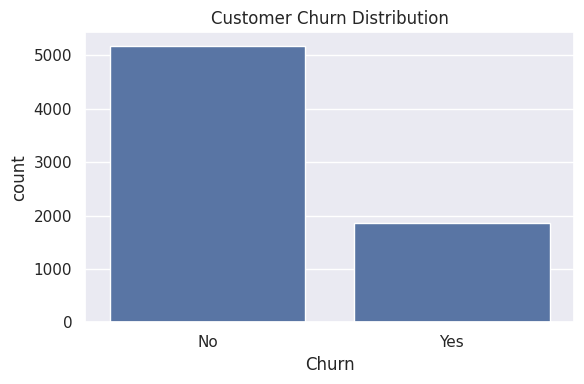

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


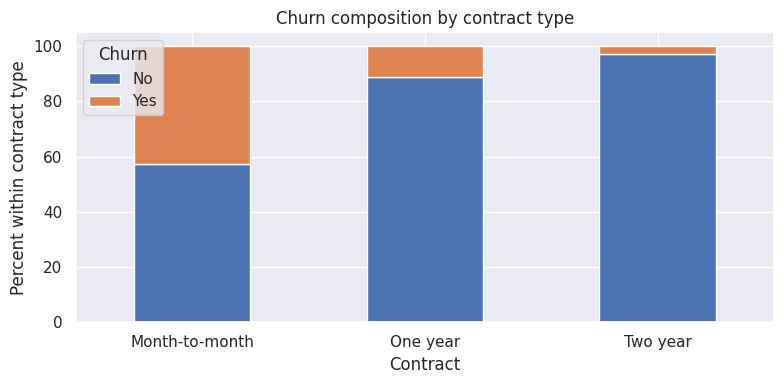

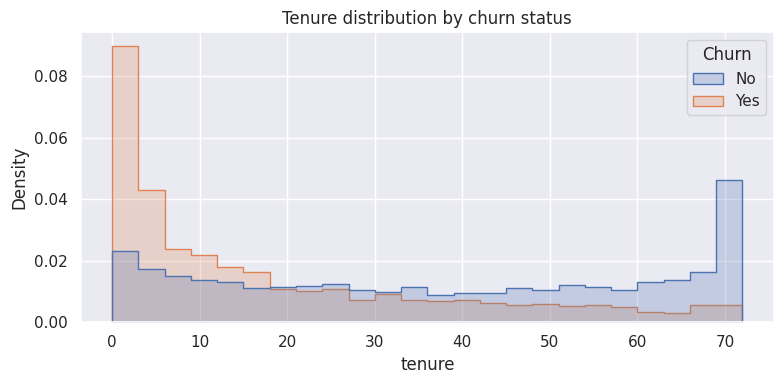

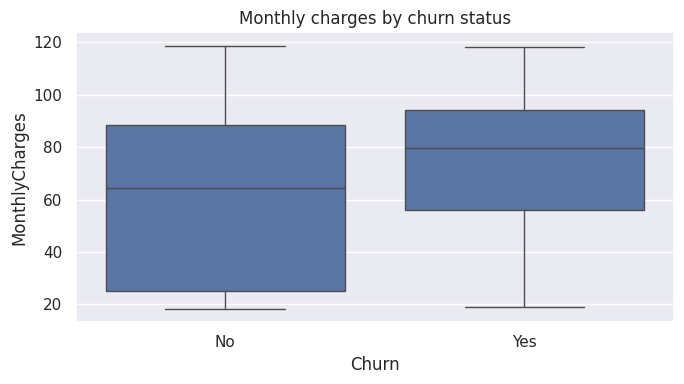

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2555.34
Yes,17.98,74.44,1531.80


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.tight_layout()
plt.show()

contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
display(contract_churn.round(2))
contract_churn.plot(kind="bar", stacked=True, figsize=(8, 4))
plt.title("Churn composition by contract type")
plt.ylabel("Percent within contract type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, element="step",
             stat="density", common_norm=False)
plt.title("Tenure distribution by churn status")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges by churn status")
plt.tight_layout()
plt.show()

display(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2))

## 5. Prepare features and split the data

In [5]:
X = df.drop(columns=["Churn", "customerID"])
y = (df["Churn"] == "Yes").astype(int)
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 5634 | Test rows: 1409


## 6. Train and compare models

In [6]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}
fitted_models = {}
metric_rows = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })
results = pd.DataFrame(metric_rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results.round(3))
best_model_name = results.index[0]
best_model = fitted_models[best_model_name]
print("Selected model (highest test ROC-AUC):", best_model_name)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.738,0.504,0.783,0.614,0.841
Random Forest,0.783,0.583,0.639,0.610,0.834


Selected model (highest test ROC-AUC): Logistic Regression


## 7. Evaluate the selected model

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



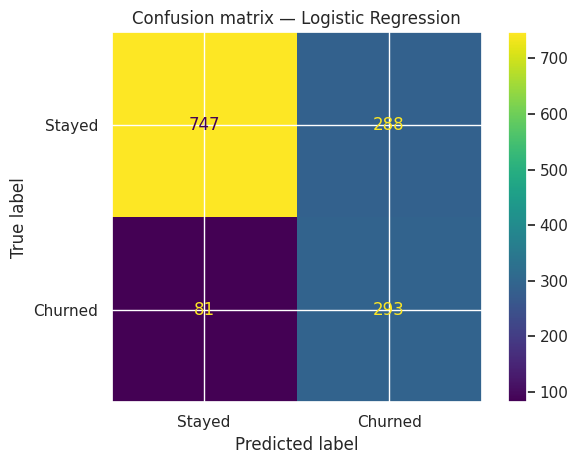

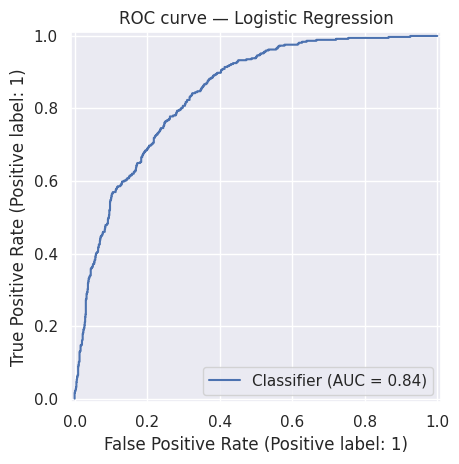

In [7]:
pred = best_model.predict(X_test)
prob = best_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=["Stayed", "Churned"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Stayed", "Churned"], values_format="d"
)
plt.title("Confusion matrix — " + best_model_name)
plt.tight_layout()
plt.show()
RocCurveDisplay.from_predictions(y_test, prob)
plt.title("ROC curve — " + best_model_name)
plt.tight_layout()
plt.show()

## 8. Business insights and recommendations

The next cell calculates churn rates from the actual dataset. Treat these as descriptive associations, not proof of cause.

In [8]:
print("Churn rate by contract type (%):")
display((pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100)
        .sort_values(ascending=False).round(2).to_frame("Churn rate (%)"))

df["TenureGroup"] = pd.cut(
    df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6 months", "7–12 months", "13–24 months", "25–48 months", "49–72 months"]
)
print("Churn rate by tenure group (%):")
display((pd.crosstab(df["TenureGroup"], df["Churn"], normalize="index")["Yes"] * 100)
        .round(2).to_frame("Churn rate (%)"))

Churn rate by contract type (%):


,Churn rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


Churn rate by tenure group (%):


,Churn rate (%)
TenureGroup,
0–6 months,52.94
7–12 months,35.89
13–24 months,28.71
25–48 months,20.39
49–72 months,9.51


### Recommendations to investigate
- Review onboarding and support for customers in their early months if their churn rate is higher.
- Investigate whether contract type, service combinations, or pricing are associated with churn.
- Use model scores to prioritize supportive outreach and human review, not automatic penalties.
- Test retention campaigns with controlled experiments before claiming that they reduce churn.

## 9. Conclusion and limitations
This notebook demonstrates an end-to-end data analytics and machine-learning workflow. Complete your final conclusion after running the notebook and reviewing the generated metrics and charts. The dataset is a fictional-company sample; results may not generalize to real businesses. Associations do not prove causation, and this random train/test split is not a time-based forecast.

## References
- IBM Telco Customer Churn: https://github.com/IBM/telco-customer-churn-on-icp4d
- pandas: https://pandas.pydata.org/docs/
- scikit-learn: https://scikit-learn.org/stable/
